# Storm Identification Pipeline — 2025
Step-by-step walkthrough of how `mstorm.py` identifies storms.
Open from inside the `asset/` folder.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta

from mstorm import (load_data, find_extrema, find_falls, combine_falls,
                    apply_conditions, identify_storms)

plt.rcParams.update({
    'axes.linewidth': 0.8, 'font.family': 'DejaVu Sans',
    'font.size': 11, 'axes.unicode_minus': False
})

def clean(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

def label(ax, text):
    ax.text(0.02, 0.97, text, transform=ax.transAxes, fontsize=9.5,
            va='top', fontweight='bold', fontfamily='monospace',
            bbox=dict(boxstyle='round,pad=0.4', fc='#fffde7', ec='gray', alpha=0.92))

In [2]:
time, sym_h = load_data('example_data.txt')
print(f'Data: {len(time)} points, {time[0].date()} to {time[-1].date()}')

Data: 525600 points, 2025-01-01 to 2025-12-31


## Step 0 — Raw SYM/H Data
Minute-resolution SYM/H from OMNIWeb. Storms appear as large negative excursions.

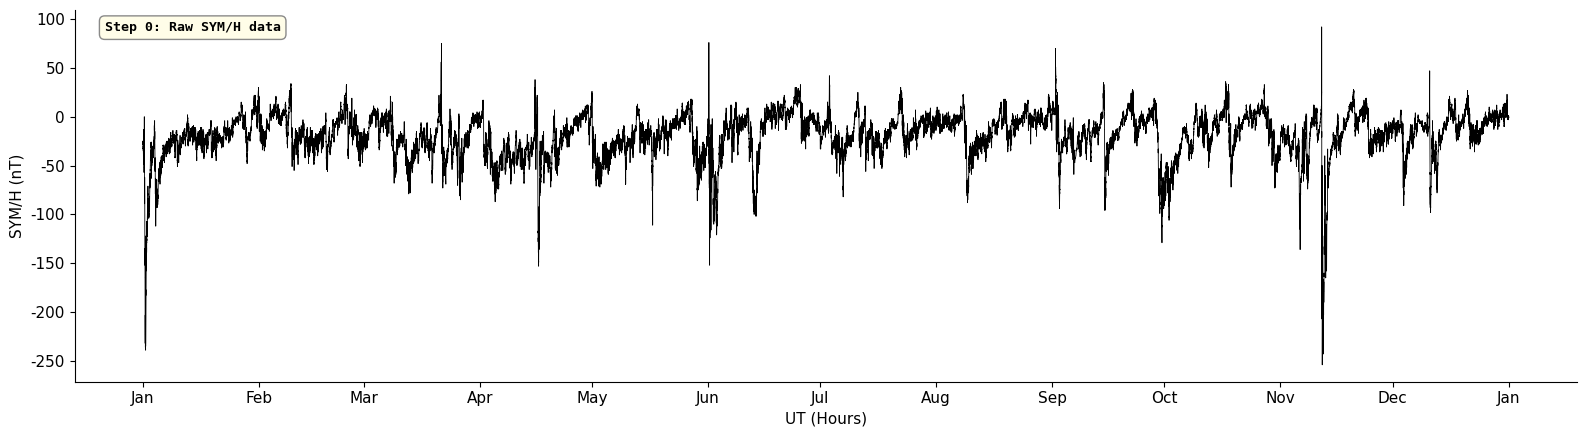

In [3]:
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.6)
ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, 'Step 0: Raw SYM/H data')
clean(ax)
plt.tight_layout()
plt.show()

## Step 1 — Local Maxima and Minima
`argrelextrema(order=1)`: every point strictly higher (▲) or lower (▼) than both neighbors.

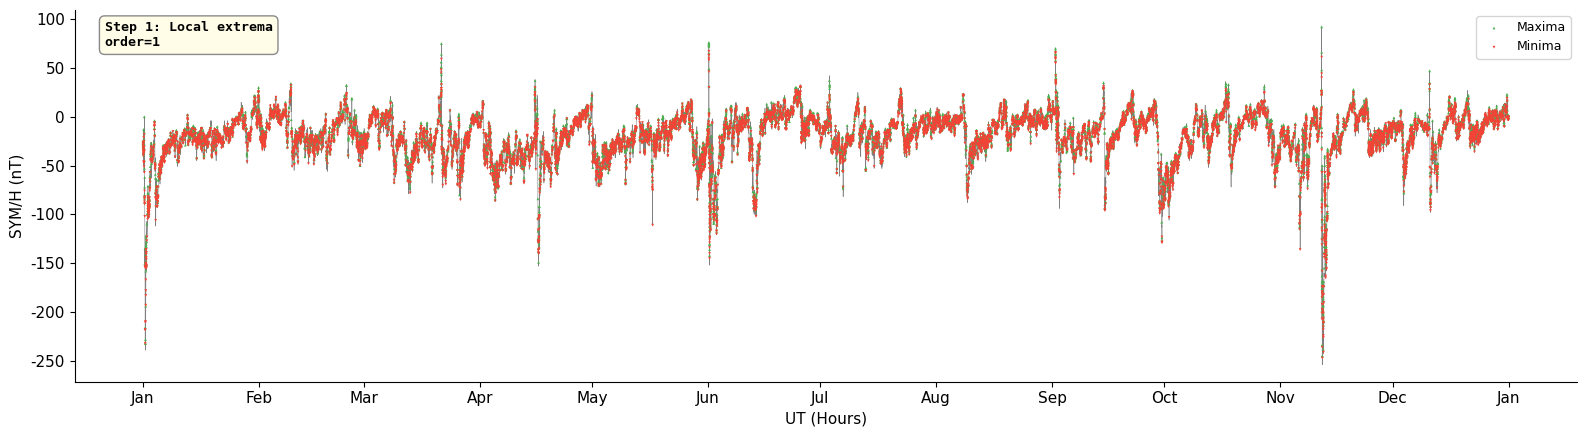

In [4]:
max_ids, min_ids = find_extrema(sym_h)

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.4, alpha=0.5)
ax.scatter(time[max_ids], sym_h[max_ids], c='#4CAF50', marker='^', s=4, zorder=5, edgecolors='none', label='Maxima')
ax.scatter(time[min_ids], sym_h[min_ids], c='#F44336', marker='v', s=4, zorder=5, edgecolors='none', label='Minima')
ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
ax.legend(loc='upper right', fontsize=9)
label(ax, 'Step 1: Local extrema\norder=1')
clean(ax)
plt.tight_layout()
plt.show()

## Step 2 — Individual Falls
Each max paired with first subsequent min. Many short blue segments — every possible downward swing.

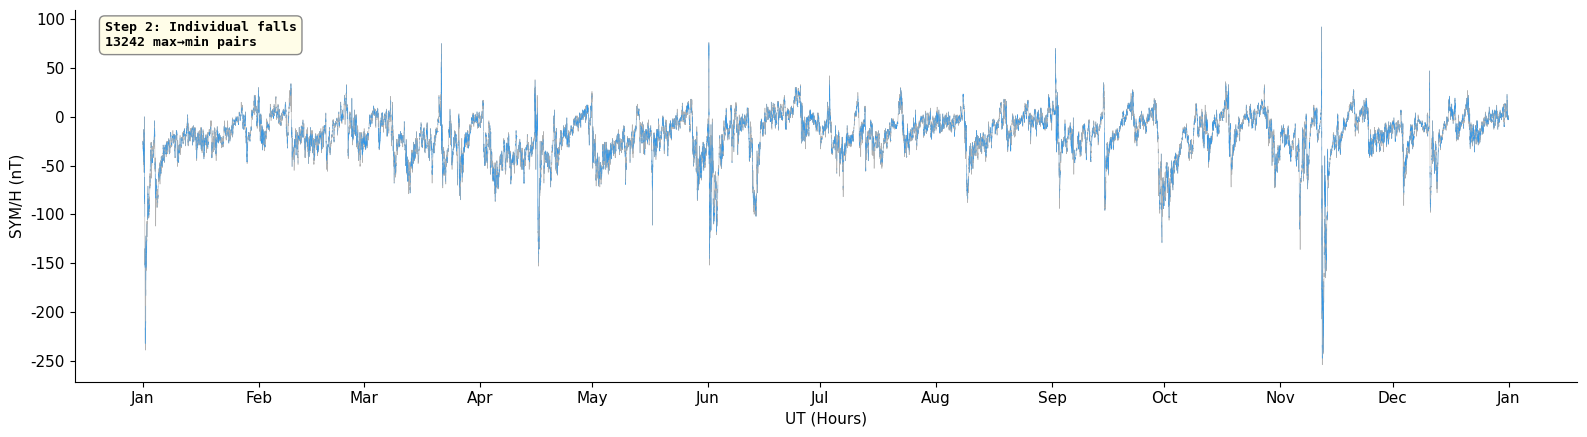

In [5]:
falls = find_falls(max_ids, min_ids)

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.4, alpha=0.3)
for fi in range(len(falls)):
    mi, mni = int(falls[fi, 0]), int(falls[fi, 1])
    ax.plot([time[mi], time[mni]], [sym_h[mi], sym_h[mni]],
            '-', color='#2196F3', linewidth=0.5, alpha=0.35)
ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Step 2: Individual falls\n{len(falls)} max\u2192min pairs')
clean(ax)
plt.tight_layout()
plt.show()

## Step 3 — Combine Nearby Falls (llimit=60 min)
Falls within 60 min merged into one region. Different colors = separate combined regions.

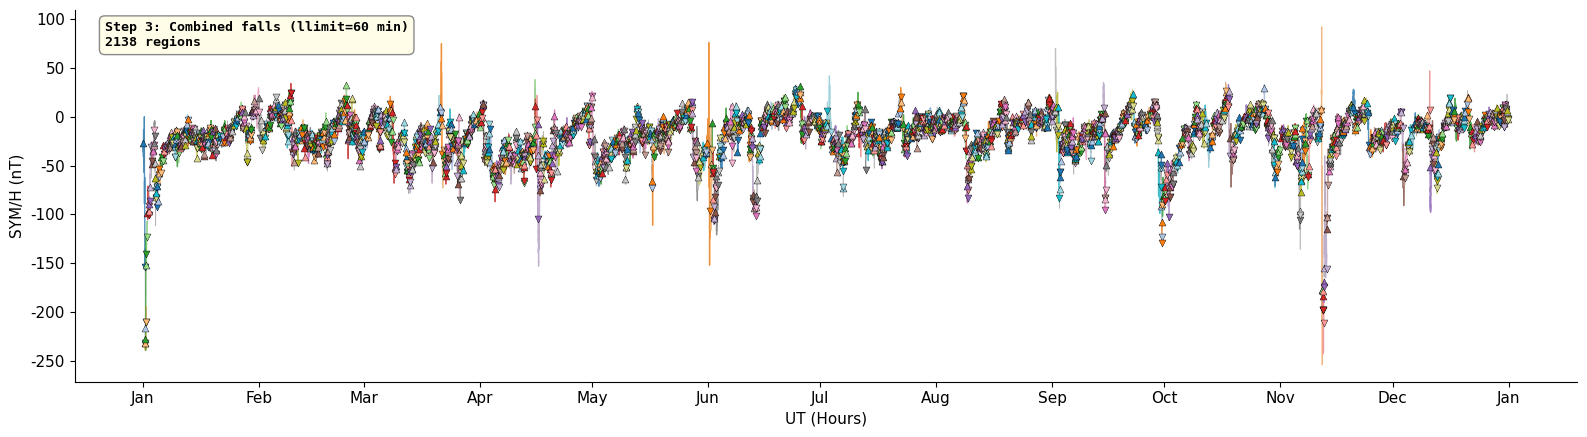

In [6]:
comb_fall = combine_falls(falls, time, 60)

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.4, alpha=0.3)
cmap = plt.cm.tab20(np.linspace(0, 1, 20))
for ci in range(len(comb_fall)):
    s, e = int(comb_fall[ci, 0]), int(comb_fall[ci, 1])
    idx = np.arange(s, e + 1)
    c = cmap[ci % 20]
    ax.plot(time[idx], sym_h[idx], '-', color=c, linewidth=1.0, alpha=0.7)
    ax.scatter(time[s], sym_h[s], c=[c], marker='^', s=25, zorder=5, edgecolors='k', linewidths=0.3)
    ax.scatter(time[e], sym_h[e], c=[c], marker='v', s=25, zorder=5, edgecolors='k', linewidths=0.3)
ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Step 3: Combined falls (llimit=60 min)\n{len(comb_fall)} regions')
clean(ax)
plt.tight_layout()
plt.show()

## Step 4 — Filter Condition 1: Minimum Depth
**Rule:** `min(SYM/H) in region > -25 nT` → removed

Too shallow — these are substorms, noise, or minor fluctuations, not geomagnetic storms. Real storms push SYM/H well below -25 nT.

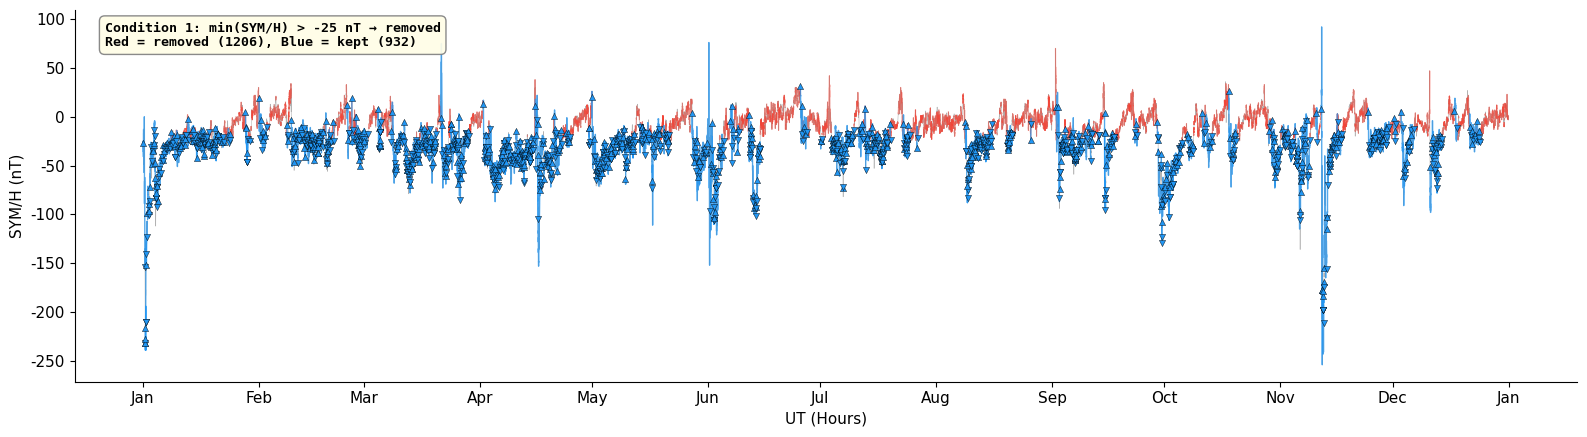

In [7]:
# Stage 1: check min depth
stage1_kept = []
stage1_removed = []
for i in range(len(comb_fall)):
    si, ei = int(comb_fall[i, 0]), int(comb_fall[i, 1])
    region_min = np.min(sym_h[si:ei+1])
    if region_min <= -25:
        stage1_kept.append(comb_fall[i])
    else:
        stage1_removed.append(comb_fall[i])

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.4, alpha=0.3)

# Removed in red (faded)
for f in stage1_removed:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[si:ei+1], sym_h[si:ei+1], '-', color='#F44336', linewidth=0.8, alpha=0.5)

# Kept in blue (bright)
for f in stage1_kept:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[si:ei+1], sym_h[si:ei+1], '-', color='#2196F3', linewidth=1.0, alpha=0.7)
    ax.scatter(time[si], sym_h[si], c='#2196F3', marker='^', s=20, zorder=5, edgecolors='k', linewidths=0.3)
    ax.scatter(time[ei], sym_h[ei], c='#2196F3', marker='v', s=20, zorder=5, edgecolors='k', linewidths=0.3)

ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Condition 1: min(SYM/H) > -25 nT → removed\nRed = removed ({len(stage1_removed)}), Blue = kept ({len(stage1_kept)})')
clean(ax)
plt.tight_layout()
plt.show()

## Step 5 — Filter Condition 2: Duration
**Rule:** `time between max and min < 2 hours` → removed

Too short — a real storm main phase lasts several hours. Quick dips are substorm-related.

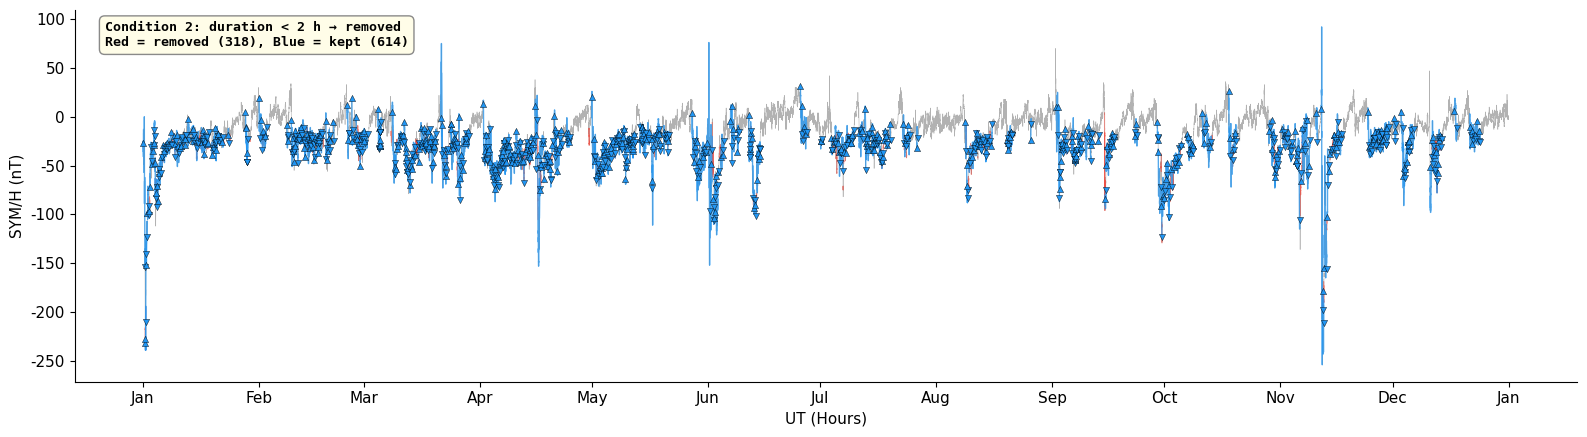

In [8]:
# Stage 2: check duration
stage2_kept = []
stage2_removed = []
for f in stage1_kept:
    si, ei = int(f[0]), int(f[1])
    diff_h = (time[ei] - time[si]).total_seconds() / 3600
    if diff_h >= 2:
        stage2_kept.append(f)
    else:
        stage2_removed.append(f)

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.4, alpha=0.3)

for f in stage2_removed:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[si:ei+1], sym_h[si:ei+1], '-', color='#F44336', linewidth=0.8, alpha=0.5)

for f in stage2_kept:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[si:ei+1], sym_h[si:ei+1], '-', color='#2196F3', linewidth=1.0, alpha=0.7)
    ax.scatter(time[si], sym_h[si], c='#2196F3', marker='^', s=20, zorder=5, edgecolors='k', linewidths=0.3)
    ax.scatter(time[ei], sym_h[ei], c='#2196F3', marker='v', s=20, zorder=5, edgecolors='k', linewidths=0.3)

ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Condition 2: duration < 2 h → removed\nRed = removed ({len(stage2_removed)}), Blue = kept ({len(stage2_kept)})')
clean(ax)
plt.tight_layout()
plt.show()

## Step 6 — Filter Condition 3: Reversed Falls
**Rule:** `max index > min index` → removed

The maximum must come before the minimum. If max is after min, the fall direction is reversed — not a valid storm main phase.

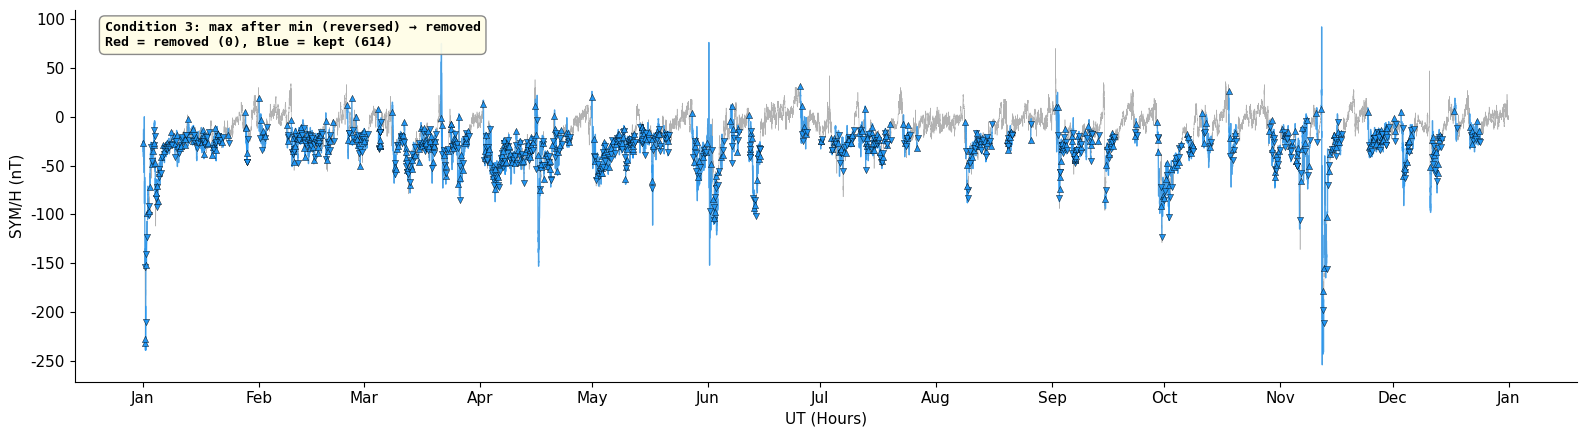

In [9]:
# Stage 3: check reversed
stage3_kept = []
stage3_removed = []
for f in stage2_kept:
    si, ei = int(f[0]), int(f[1])
    if si > ei:
        stage3_removed.append(f)
    else:
        stage3_kept.append(f)

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.4, alpha=0.3)

for f in stage3_removed:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[min(si,ei):max(si,ei)+1], sym_h[min(si,ei):max(si,ei)+1],
            '-', color='#F44336', linewidth=1.5, alpha=0.7)

for f in stage3_kept:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[si:ei+1], sym_h[si:ei+1], '-', color='#2196F3', linewidth=1.0, alpha=0.7)
    ax.scatter(time[si], sym_h[si], c='#2196F3', marker='^', s=20, zorder=5, edgecolors='k', linewidths=0.3)
    ax.scatter(time[ei], sym_h[ei], c='#2196F3', marker='v', s=20, zorder=5, edgecolors='k', linewidths=0.3)

ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Condition 3: max after min (reversed) → removed\nRed = removed ({len(stage3_removed)}), Blue = kept ({len(stage3_kept)})')
clean(ax)
plt.tight_layout()
plt.show()

## Step 7 — Filter Condition 4: Amplitude
**Rule:** `|max - min| < 50 nT` → removed

Too small. A real storm has a significant drop from peak to trough. Minor wiggles are filtered out.

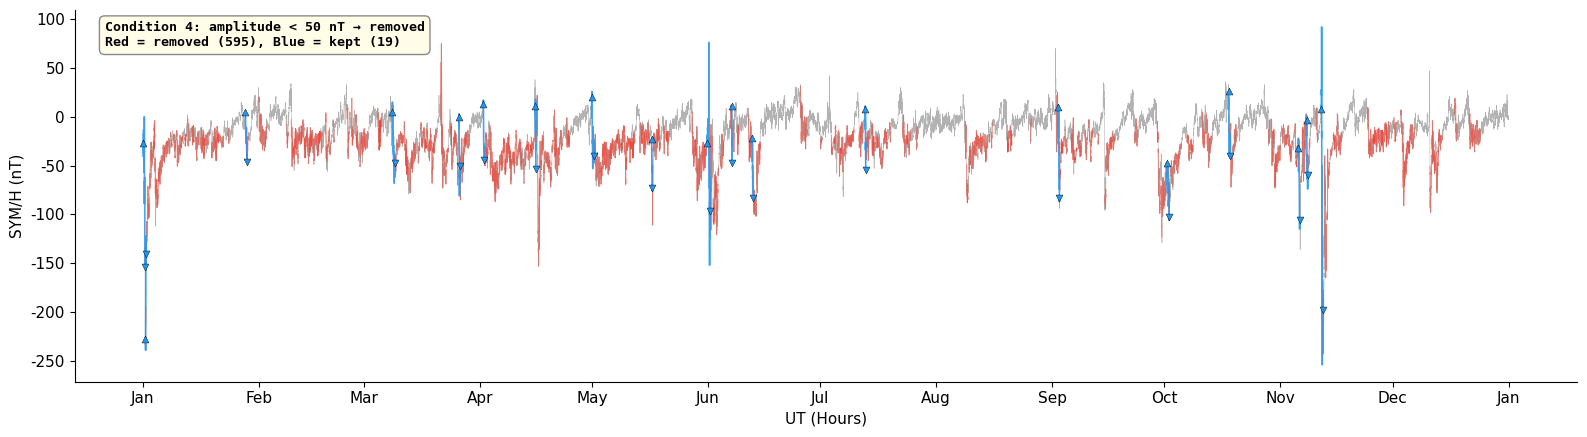

In [10]:
# Stage 4: check amplitude
stage4_kept = []
stage4_removed = []
for f in stage3_kept:
    si, ei = int(f[0]), int(f[1])
    amp = np.abs(sym_h[ei] - sym_h[si])
    if amp >= 50:
        stage4_kept.append(f)
    else:
        stage4_removed.append(f)

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.4, alpha=0.3)

for f in stage4_removed:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[si:ei+1], sym_h[si:ei+1], '-', color='#F44336', linewidth=0.8, alpha=0.5)

for f in stage4_kept:
    si, ei = int(f[0]), int(f[1])
    ax.plot(time[si:ei+1], sym_h[si:ei+1], '-', color='#2196F3', linewidth=1.2, alpha=0.8)
    ax.scatter(time[si], sym_h[si], c='#2196F3', marker='^', s=25, zorder=5, edgecolors='k', linewidths=0.3)
    ax.scatter(time[ei], sym_h[ei], c='#2196F3', marker='v', s=25, zorder=5, edgecolors='k', linewidths=0.3)

ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Condition 4: amplitude < 50 nT → removed\nRed = removed ({len(stage4_removed)}), Blue = kept ({len(stage4_kept)})')
clean(ax)
plt.tight_layout()
plt.show()

## Step 8 — Merge Gaps + Rate Check
**Merge:** qualified falls within 10 h of each other are joined into one storm.
**Rate:** `(max - min) / time < -5 nT/h` — must be a sustained decrease.

These remaining colored segments are the final qualified storm candidates.

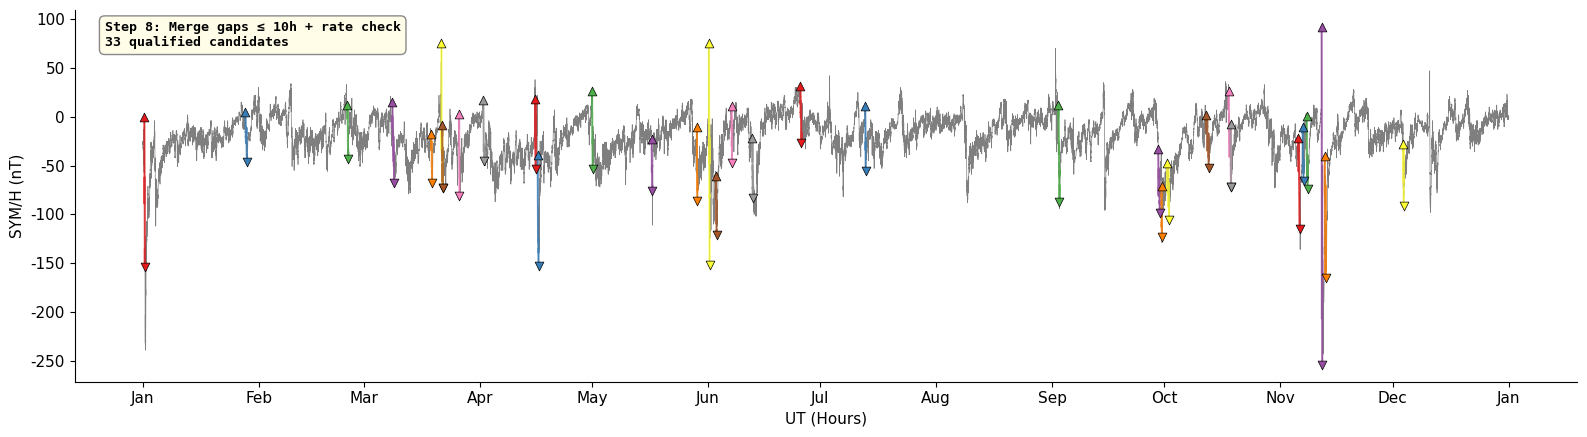

In [11]:
fourth_datetime, fourth_sym_h = apply_conditions(comb_fall, time, sym_h)

fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(time, sym_h, '-k', linewidth=0.5, alpha=0.5)
cmap2 = plt.cm.Set1(np.linspace(0, 1, 9))
for fi in range(len(fourth_sym_h)):
    fd, fs = fourth_datetime[fi], fourth_sym_h[fi]
    c = cmap2[fi % 9]
    ax.plot(fd, fs, '-', color=c, linewidth=1.5, alpha=0.8)
    ax.scatter(fd[0], fs[0], c=[c], marker='^', s=40, zorder=5, edgecolors='k', linewidths=0.5)
    ax.scatter(fd[-1], fs[-1], c=[c], marker='v', s=40, zorder=5, edgecolors='k', linewidths=0.5)
ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Step 8: Merge gaps \u2264 10h + rate check\n{len(fourth_sym_h)} qualified candidates')
clean(ax)
plt.tight_layout()
plt.show()

## Step 9 — Final Storm Identification
MPO (peak before main phase) and MIN (deepest point) identified for each candidate.
10-hour lookahead corrects MIN to deepest nearby point.

- **Blue line**: storm main phase + recovery
- **Yellow band**: MPO → MIN interval
- **Green arrow**: MPO value and time
- **Red arrow**: MIN value and time

In [12]:
storm_table = identify_storms(fourth_datetime, fourth_sym_h, time, sym_h)
print(f'Final storms: {len(storm_table)}')
print(f'{"MPO":>8} {"Time":>18} {"MIN":>8} {"Time":>18} {"Ips":>8}')
print('-' * 65)
for s in storm_table:
    print(f"{s['MPO']:>8.0f} {str(s['MPO_Datetime']):>18} {s['MIN']:>8.0f} {str(s['MIN_Datetime']):>18} {s['Ips']:>8.2f}")

Final storms: 30
     MPO               Time      MIN               Time      Ips
-----------------------------------------------------------------
       0 2025-01-01 08:47:00     -239 2025-01-01 16:40:00   -46.43
      12 2025-02-24 13:17:00      -43 2025-02-24 20:35:00    -7.05
      15 2025-03-08 16:15:00      -68 2025-03-09 03:05:00   -29.46
     -18 2025-03-18 23:18:00      -68 2025-03-19 06:39:00   -34.51
      75 2025-03-21 18:27:00      -73 2025-03-22 03:22:00   -31.44
      -8 2025-03-21 22:48:00      -73 2025-03-22 03:22:00   -39.53
       3 2025-03-26 10:37:00      -85 2025-03-26 20:23:00    -8.32
      17 2025-04-02 00:00:00      -50 2025-04-02 08:21:00   -22.13
      18 2025-04-15 21:47:00      -54 2025-04-16 00:16:00   -17.98
     -39 2025-04-16 12:08:00     -153 2025-04-16 17:43:00  -115.10
      26 2025-05-01 00:09:00      -53 2025-05-01 05:07:00   -30.22
     -23 2025-05-16 22:45:00     -111 2025-05-17 05:16:00   -31.86
     -10 2025-05-29 00:45:00      -86 2025-05-29

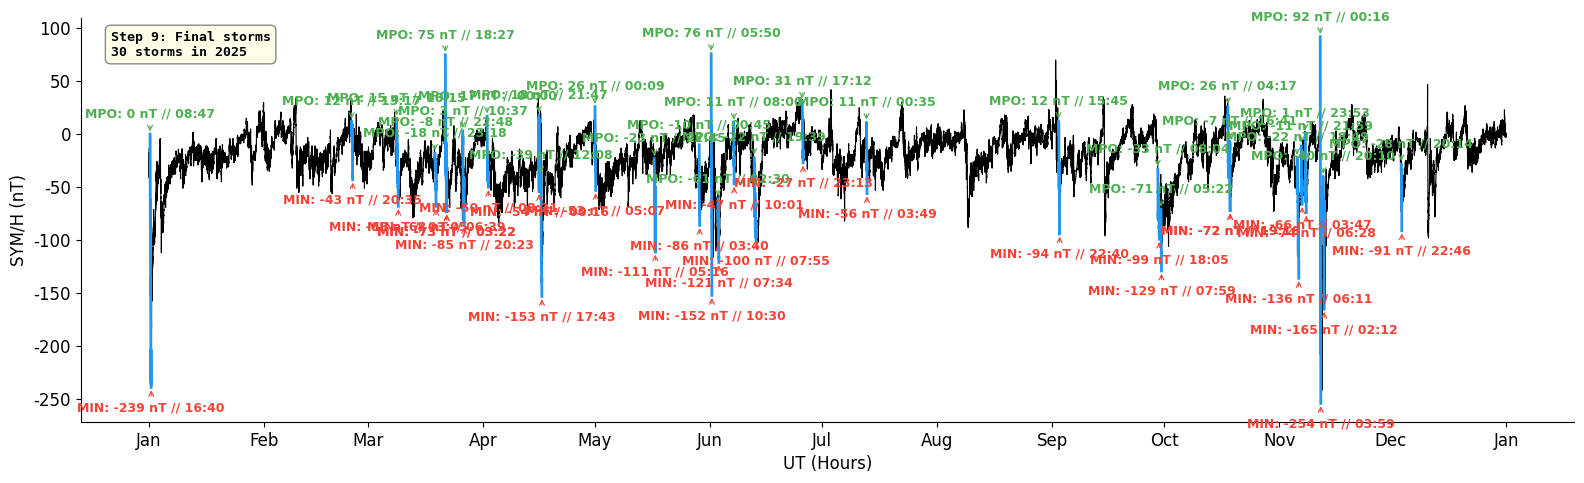

In [13]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(time, sym_h, '-k', linewidth=0.8)

for s in storm_table:
    fi = s['Fall_Index']
    sdt, ssh = fourth_datetime[fi], fourth_sym_h[fi]
    mpo_dt, min_dt = s['MPO_Datetime'], s['MIN_Datetime']

    if min_dt > sdt[-1]:
        ext = (time > sdt[-1]) & (time <= min_dt)
        if np.any(ext):
            sdt = np.concatenate([sdt, time[ext]])
            ssh = np.concatenate([ssh, sym_h[ext]])

    _, uid = np.unique(sdt, return_index=True)
    uid = np.sort(uid)
    ax.plot(sdt[uid], ssh[uid], '-', color='#2196F3', linewidth=2.0)
    ax.fill_between([mdates.date2num(mpo_dt), mdates.date2num(min_dt)],
                    s['MIN'], s['MPO'], alpha=0.2, color='#FFC107')

    ax.annotate(f"MPO: {s['MPO']:.0f} nT // {mpo_dt.strftime('%H:%M')}",
                xy=(mpo_dt, s['MPO']), fontsize=9, fontweight='bold', color='#4CAF50',
                ha='center', va='bottom', xytext=(0, 10), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='#4CAF50', lw=0.8))
    ax.annotate(f"MIN: {s['MIN']:.0f} nT // {min_dt.strftime('%H:%M')}",
                xy=(min_dt, s['MIN']), fontsize=9, fontweight='bold', color='#F44336',
                ha='center', va='top', xytext=(0, -10), textcoords='offset points',
                arrowprops=dict(arrowstyle='->', color='#F44336', lw=0.8))

ax.set_ylabel('SYM/H (nT)')
ax.set_xlabel('UT (Hours)')
label(ax, f'Step 9: Final storms\n{len(storm_table)} storms in 2025')
clean(ax)
plt.tight_layout()
plt.show()

## Summary

| Step | What happens |
|------|-------------|
| 0 | Raw SYM/H data |
| 1 | Find local maxima (▲) and minima (▼) |
| 2 | Pair each max with first subsequent min → individual falls |
| 3 | Merge falls within llimit (60 min) → combined regions |
| 4 | **Condition 1**: remove regions where min > −25 nT (too shallow) |
| 5 | **Condition 2**: remove regions where duration < 2 h (too short) |
| 6 | **Condition 3**: remove regions where max after min (reversed) |
| 7 | **Condition 4**: remove regions where amplitude < 50 nT (too small) |
| 8 | Merge gaps ≤ 10 h + rate check (max−min)/time < −5 nT/h |
| 9 | Identify MPO, MIN, Ips, Revised_Min, Revised_Ips with 10h lookahead |